In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2
import os
from importlib import reload
import matplotlib.pyplot as plt
from ORG import pipeline
import numpy as np
import matplotlib
matplotlib.rcParams['image.cmap'] = 'gray'

current_directory = os.getcwd()
retina = pipeline.retina(current_directory)

In [61]:
retina.load_config()
retina.isetbio_mosaic()

System parameters file: /home/siruil/ERICA/System_parameters/system_parameters_myAOSLO.yaml
Cone reflectance parameter file: /home/siruil/ERICA/Reflectance_parameters/cone_reflectance_parameters.yaml
Eye movements parameter file: /home/siruil/ERICA/Fixation_parameters/fixation_parameters_default.yaml
Unscaled mosaic grid file: /mnt/d/Sirui/project/AOSLO_ORG/Code/simulation/isetbio_retina/mosaic_00.mat


0.866188364888514


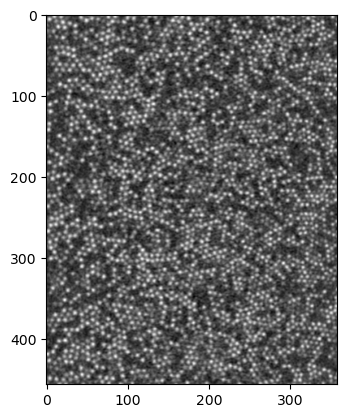

In [62]:
im = retina.make_aoslo_image()
print(np.nanstd(im)/np.nanmean(im))
plt.imshow(im)

In [18]:
import datetime
date_stamp = datetime.datetime.now()
date_stamp = date_stamp.date()
image_dir = f'./experiments/{date_stamp}/image_sequence/'
print(f'Reading pre-calculated trials meta: {os.path.join(image_dir, "trials_meta.npy")}')
trials_meta = np.load(os.path.join(image_dir, "trials_meta.npy"), allow_pickle=True).item()

Reading pre-calculated trials meta: ./experiments/2026-01-21/image_sequence/trials_meta.npy


eccentricity: [0.0, -1.5]
field of view: [2, 2]


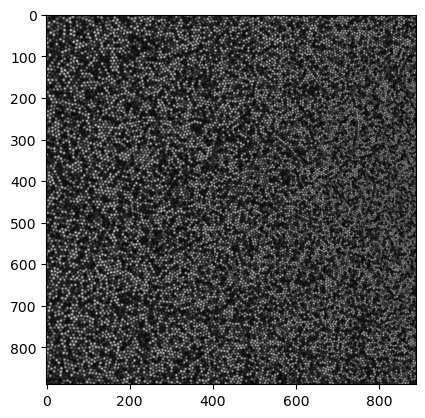

In [63]:
montage, groundtruth, cones_scanned = retina.make_montage()
plt.imshow(montage)

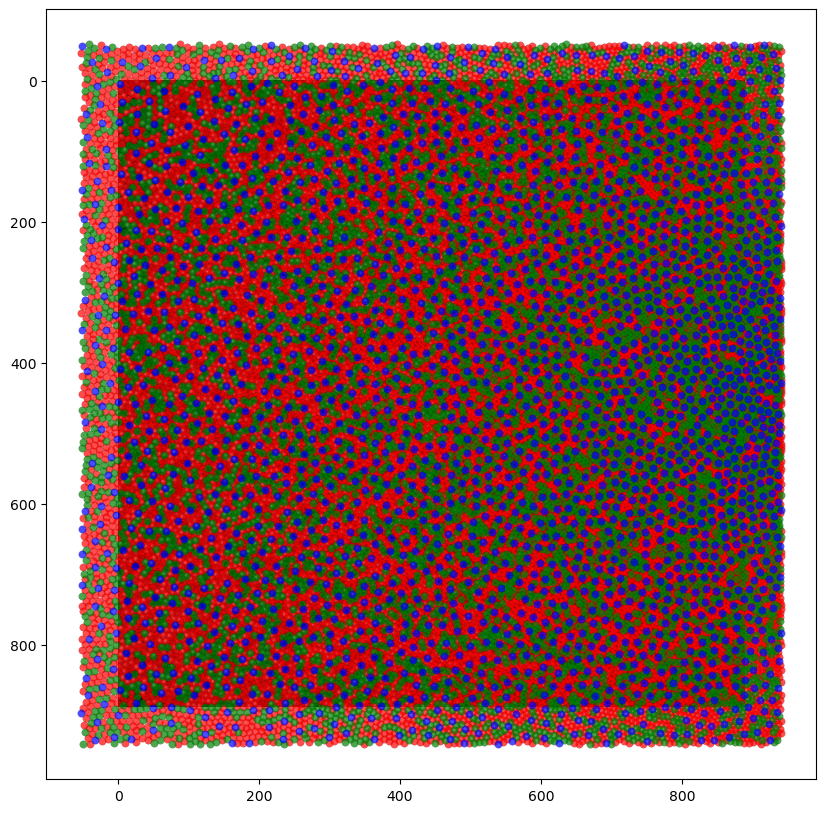

In [64]:
fig, ax = plt.subplots(figsize=(10,10))

ax.imshow(montage)
# ax.scatter(groundtruth[1], groundtruth[0], s=1)
# ax.scatter(retina_params_pixels_scanned[1], -retina_params_pixels_scanned[0], s=2)

cone_types = retina.mosaic['cone_types'][cones_scanned]
colors = {1:'red', 2:'green', 3:'blue'}
labels = {1:'L cone', 2:'M cone', 3:'S cone'}
alpha_vals = [0.7, 0.7, 0.7]
for cone_type in [1, 2, 3]:
    idx = cone_types == cone_type
    ax.scatter(groundtruth[1, idx], groundtruth[0, idx], s=30, c=colors[cone_type], label=labels[cone_type], edgecolors='black', linewidths=0.1, alpha=alpha_vals[cone_type-1])

plt.show()

fig.savefig("montage_mosaic.svg")

In [71]:
import cv2
montage_norm = 255 * ( montage - montage.min()) / (montage.max() - montage.min())
cv2.imwrite('montage_-1p5temporal.bmp', montage_norm)

True

In [65]:
np.save('montage_mosaic_groundtruth.npy', groundtruth[0:2])

In [66]:
import scipy
var = {"groundtruth": groundtruth[0:2], "mosaic": cone_types}
scipy.io.savemat('montage_mosaic_groundtruth.mat', var)

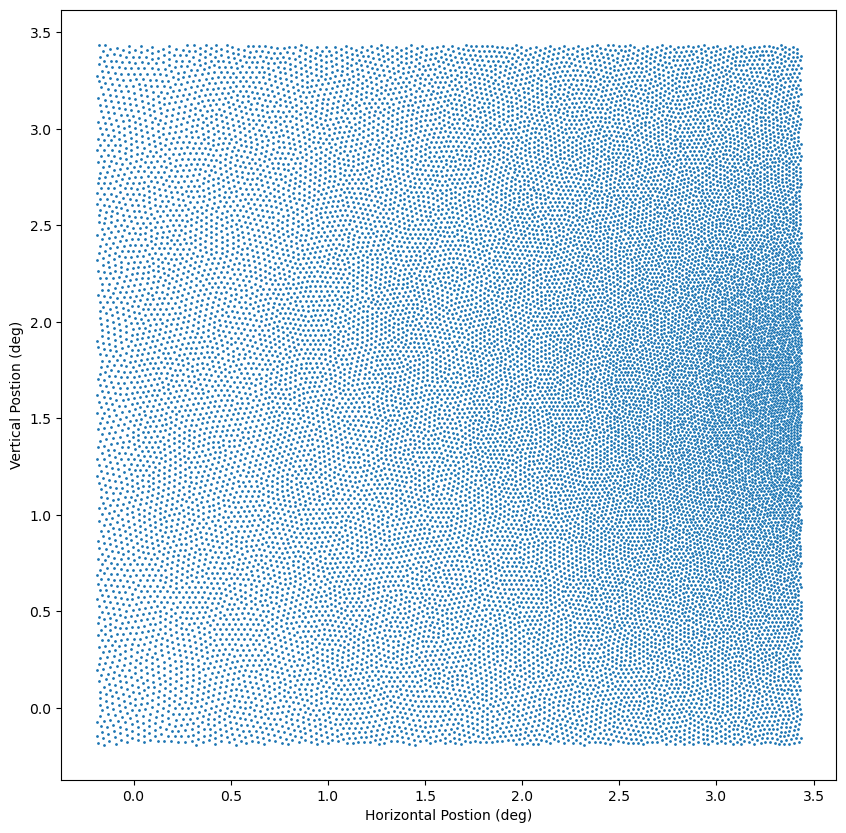

In [67]:
from ORG.visualisation import visualise_mosaic_grid
visualise_mosaic_grid(groundtruth[0:2], microns_per_degree=retina.myAOSLO.parameters['microns_per_degree'])